# 06— Probabilistic Host Inference

**Goal:** estimate whether each planet in a Sullivan et al. (2024) unresolved binary system orbits the primary or secondary star, using the Kepler transit-derived stellar density as the discriminating observable.

For each planet, the notebook compares the transit density, \(\rho_{\rm tr}\), with the density estimates for the two stellar components. With baseline equal priors,

\[
P(H_j\mid D) = \frac{P(D\mid H_j)P(H_j)}{\sum_{k\in\{1,2\}}P(D\mid H_k)P(H_k)},
\qquad P(H_1)=P(H_2)=0.5.
\]

This is a **density-based, two-hypothesis approximation**, not a complete physical host model. Equal priors are a baseline assumption. The likelihood approximates measurement and stellar-density uncertainties as independent; this ignores potential covariance, eccentricity effects, and transit-model systematics. Those caveats must accompany any interpretation of the resulting probabilities.

**Input priority:** use the current quality-controlled planet-level Sullivan table; otherwise use the older `binary_stellar_properties.csv`. If transit-density columns are absent, the notebook attempts to join them from the Kepler DR25 KOI table by normalized planet identifier. It deliberately stops with an informative error if the required observations or stellar-density estimates cannot be found.

Run from the project root so the relative `data/` paths resolve correctly.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(".")
PROCESSED = ROOT / "data" / "processed"
DR25_FILE = ROOT / "data" / "raw" / "nasa" / "nasa_kepler_dr25_koi.csv"

# Prefer the current Sullivan 2024 + MIST quality-controlled output.
# Fall back to the legacy combined file if the current file is absent.
INPUT_CANDIDATES = [
    PROCESSED / "sullivan2024_planets_quality_controlled.csv",
    PROCESSED / "sullivan2024_planets_with_mist_properties_all.csv",
    PROCESSED / "binary_stellar_properties.csv",
]

OUTPUT_FILE = PROCESSED / "binary_host_probability_catalog.csv"
SUMMARY_FILE = PROCESSED / "binary_host_probability_summary.csv"
SENSITIVITY_FILE = PROCESSED / "binary_host_probability_sensitivity.csv"

# Baseline priors: neutral between the two components.
P_PRIOR_PRIMARY = 0.5
P_PRIOR_SECONDARY = 0.5

# Used ONLY if the input file has no propagated stellar-density uncertainty.
# This preserves the old 5% approximation but flags it as a fallback.
FALLBACK_MODEL_FRAC_SCATTER = 0.05
FALLBACK_SCATTER_TESTS = (0.05, 0.10, 0.20)

# Multipliers for the uncertainty reported by the MIST/density pipeline.
# The baseline result uses 1.0; 1.5 and 2.0 are sensitivity tests.
MODEL_SIGMA_INFLATION_TESTS = (1.0, 1.5, 2.0)

PROCESSED.mkdir(parents=True, exist_ok=True)

existing_inputs = [path for path in INPUT_CANDIDATES if path.is_file()]
if not existing_inputs:
    raise FileNotFoundError(
        "No suitable planet-level input table was found. Expected one of:\n"
        + "\n".join(str(p.resolve()) for p in INPUT_CANDIDATES)
        + "\nRun Notebook 04 first, or place the legacy binary_stellar_properties.csv in data/processed."
    )

INPUT_FILE = existing_inputs[0]
df = pd.read_csv(INPUT_FILE, low_memory=False)
print("Input:", INPUT_FILE)
print("Rows, columns:", df.shape)
print("Columns loaded:", len(df.columns))
display(df.head(3))

Input: data\processed\sullivan2024_planets_quality_controlled.csv
Rows, columns: (396, 143)
Columns loaded: 143


,KOI,KOIpl,Rppri,E_Rppri,e_Rppri,Rpsec,E_Rpsec,e_Rpsec,Rpkep,e_Rpkep,...,e_fcorr-s,Source,K16,F17,Simbad_stellar,_RA_stellar,_DE_stellar,catalogue_metadata_match,has_mist_match,passes_mist_quality_cut
0,42,42.01,2.28,0.14,0.14,4.89,0.32,0.33,2.43,0.12,...,0.09,1,1,1,Simbad,283.15067,45.13982,True,True,True
1,112,112.01,3.55,0.72,0.72,4.74,0.98,0.98,2.75,0.39,...,0.21,2,1,1,Simbad,295.64868,48.49555,True,True,True
2,112,112.02,1.49,0.29,0.30,1.98,0.38,0.40,1.16,0.17,...,0.21,2,1,1,Simbad,295.64868,48.49555,True,True,True


## 1. Validate planet identifiers and transit-density data

`KOIpl` identifies a planet; `KOI` identifies the binary system. Transit density is planet-specific, so the join to the Kepler KOI catalogue must use the planet identifier, not only the system identifier.

In [2]:
def normalize_planet_id(value):
    """Normalize 2535.01, K002535.01, and similar identifiers to '2535.01'."""
    if pd.isna(value):
        return pd.NA
    text = str(value).strip().upper()
    match = re.search(r"(\d+)\s*(?:\.\s*(\d+))?", text)
    if match is None or match.group(2) is None:
        return pd.NA
    system_number = int(match.group(1))
    planet_number = int(match.group(2))
    return f"{system_number}.{planet_number:02d}"

if "KOIpl" not in df.columns:
    raise KeyError(
        "The input table has no 'KOIpl' planet identifier. The host probabilities must be calculated per planet."
    )

df["_planet_key"] = df["KOIpl"].map(normalize_planet_id).astype("string")
if df["_planet_key"].isna().any():
    examples = df.loc[df["_planet_key"].isna(), "KOIpl"].head(10).tolist()
    raise ValueError(f"Some KOIpl values could not be normalized as planet IDs: {examples}")
if df["_planet_key"].duplicated().any():
    examples = df.loc[df["_planet_key"].duplicated(keep=False), "_planet_key"].head(10).tolist()
    raise ValueError(
        "Input table should have one row per planet. Duplicate normalized IDs found, e.g. "
        f"{examples}. Check the merge/input before calculating probabilities."
    )

transit_cols = ["koi_srho", "koi_srho_err1", "koi_srho_err2"]
missing_transit_cols = [col for col in transit_cols if col not in df.columns]

if missing_transit_cols:
    if not DR25_FILE.is_file():
        raise FileNotFoundError(
            "Transit-density columns are missing from the input: "
            f"{missing_transit_cols}. The expected Kepler DR25 file is also missing: "
            f"{DR25_FILE.resolve()}. Add the DR25 file or provide these columns in the input table."
        )

    dr25 = pd.read_csv(DR25_FILE, low_memory=False)
    if "kepoi_name" in dr25.columns:
        dr25_id_col = "kepoi_name"
    elif "KOIpl" in dr25.columns:
        dr25_id_col = "KOIpl"
    else:
        raise KeyError(
            "Could not find a planet identifier in the DR25 file. Expected 'kepoi_name' or 'KOIpl'."
        )

    required_dr25 = [dr25_id_col] + [c for c in transit_cols if c in dr25.columns]
    missing_dr25 = [c for c in transit_cols if c not in dr25.columns]
    if missing_dr25:
        raise KeyError(f"Kepler DR25 table is missing required transit-density columns: {missing_dr25}")

    dr25_small = dr25[required_dr25].copy()
    dr25_small["_planet_key"] = dr25_small[dr25_id_col].map(normalize_planet_id).astype("string")
    dr25_small = dr25_small.dropna(subset=["_planet_key"])
    duplicated_dr25 = dr25_small["_planet_key"].duplicated(keep=False)
    if duplicated_dr25.any():
        examples = dr25_small.loc[duplicated_dr25, "_planet_key"].head(10).tolist()
        raise ValueError(
            "DR25 has duplicate normalized planet IDs, so the density join is ambiguous. "
            f"Examples: {examples}"
        )

    # Bring over only fields missing from the primary input; never silently overwrite existing values.
    add_cols = [c for c in missing_transit_cols if c in dr25_small.columns]
    dr25_join = dr25_small[["_planet_key"] + add_cols]
    df = df.merge(dr25_join, on="_planet_key", how="left", validate="one_to_one")
    print("Joined missing Kepler DR25 density columns by planet ID:", add_cols)

missing_transit_cols = [col for col in transit_cols if col not in df.columns]
if missing_transit_cols:
    raise KeyError(f"Transit-density columns still missing after attempted join: {missing_transit_cols}")

# Numeric conversion: invalid/non-finite values are flagged and retained with NaN probabilities.
for col in transit_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Kepler asymmetric errors may be signed; use the absolute magnitudes to form a symmetric approximation.
df["rho_transit_gcm3"] = df["koi_srho"]
df["sigma_transit_gcm3"] = 0.5 * (
    df["koi_srho_err1"].abs() + df["koi_srho_err2"].abs()
)

print("Rows:", len(df))
print("Missing/non-finite transit density:", (~np.isfinite(df["rho_transit_gcm3"])).sum())
print("Missing/non-positive transit uncertainty:", (~np.isfinite(df["sigma_transit_gcm3"]) | (df["sigma_transit_gcm3"] <= 0)).sum())
display(df[["KOIpl", "rho_transit_gcm3", "sigma_transit_gcm3"]].head(10))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\1421406776.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["_planet_key"] = df["KOIpl"].map(normalize_planet_id).astype("string")


Joined missing Kepler DR25 density columns by planet ID: ['koi_srho', 'koi_srho_err1', 'koi_srho_err2']
Rows: 396
Missing/non-finite transit density: 33
Missing/non-positive transit uncertainty: 35


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\1421406776.py:81: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["rho_transit_gcm3"] = df["koi_srho"]
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\1421406776.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["sigma_transit_gcm3"] = 0.5 * (


,KOIpl,rho_transit_gcm3,sigma_transit_gcm3
0,42.01,1.72198,0.131390
1,112.01,1.79031,0.128355
2,112.02,1.77451,0.319880
3,162.01,0.71331,0.472690
4,163.01,0.94776,1.036495
5,165.01,4.04712,1.023485
6,174.01,2.63903,4.865140
7,177.01,1.23168,0.229375
8,191.01,1.85072,0.081680
9,191.02,2.46233,0.448050


## 2. Select the stellar-density estimates and uncertainties

The current joint-MIST workflow outputs `rho1_joint_gcm3` / `rho2_joint_gcm3` and lower/upper uncertainty estimates. The older workflow uses `rho1_MIST` / `rho2_MIST`. Where propagated uncertainties are not available, the notebook uses the historical 5% fractional-scatter approximation only as an explicit fallback and reports it.

In [3]:
# Identify the density columns available in this file.
if {"rho1_joint_gcm3", "rho2_joint_gcm3"}.issubset(df.columns):
    RHO1_COL, RHO2_COL = "rho1_joint_gcm3", "rho2_joint_gcm3"
    model_family = "joint_MIST_mass_plus_catalogue_radius_density"
elif {"rho1_MIST", "rho2_MIST"}.issubset(df.columns):
    RHO1_COL, RHO2_COL = "rho1_MIST", "rho2_MIST"
    model_family = "joint_MIST_mass_plus_catalogue_radius_density"
else:
    # A constrained fallback: derive density from MIST median mass and measured component radius.
    if {"M1_50", "M2_50", "Rstar1", "Rstar2"}.issubset(df.columns):
        RHO_SUN_GCM3 = 1.408
        for component in (1, 2):
            mass_col = f"M{component}_50"
            radius_col = f"Rstar{component}"
            df[f"rho{component}_derived_gcm3"] = (
                RHO_SUN_GCM3
                * pd.to_numeric(df[mass_col], errors="coerce")
                / pd.to_numeric(df[radius_col], errors="coerce") ** 3
            )
        RHO1_COL, RHO2_COL = "rho1_derived_gcm3", "rho2_derived_gcm3"
        model_family = "derived_from_MIST_median_mass_and_catalogue_radius"
    else:
        raise KeyError(
            "Could not find either ('rho1_MIST','rho2_MIST'), "
            "('rho1_joint_gcm3','rho2_joint_gcm3'), or the required M1_50/M2_50/Rstar1/Rstar2 columns."
        )

for col in [RHO1_COL, RHO2_COL]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Search for propagated lower/upper uncertainties from the current MIST workflow.
model_uncertainty_available = (RHO1_COL == "rho1_joint_gcm3") and all(
    c in df.columns for c in [
        "rho1_joint_err_low", "rho1_joint_err_high",
        "rho2_joint_err_low", "rho2_joint_err_high",
    ]
)

if model_uncertainty_available:
    # Use side-specific uncertainties in the baseline likelihood.
    for component in (1, 2):
        for side in ("low", "high"):
            col = f"rho{component}_joint_err_{side}"
            df[col] = pd.to_numeric(df[col], errors="coerce").abs()
    uncertainty_source = "propagated_joint_MIST_density_errors"
else:
    # Also recognize common legacy names if present.
    candidate_pairs = [
        ("rho1_MIST_err_low", "rho1_MIST_err_high", "rho2_MIST_err_low", "rho2_MIST_err_high"),
        ("rho1_err_low", "rho1_err_high", "rho2_err_low", "rho2_err_high"),
    ]
    found_pair = None
    for pair in candidate_pairs:
        if all(col in df.columns for col in pair):
            found_pair = pair
            break
    if found_pair is not None:
        for component, low_col, high_col in [(1, found_pair[0], found_pair[1]), (2, found_pair[2], found_pair[3])]:
            df[f"_rho{component}_err_low"] = pd.to_numeric(df[low_col], errors="coerce").abs()
            df[f"_rho{component}_err_high"] = pd.to_numeric(df[high_col], errors="coerce").abs()
        uncertainty_source = "provided_legacy_density_errors"
    else:
        uncertainty_source = "fallback_fractional_scatter"
        warnings.warn(
            "No propagated density uncertainties found. A provisional fractional model scatter will be used. "
            "Interpret probabilities cautiously and inspect the sensitivity analysis.",
            RuntimeWarning,
        )

print("Density columns:", RHO1_COL, RHO2_COL)
print("Density model:", model_family)
print("Model uncertainty source:", uncertainty_source)
print("Joint MIST uncertainty columns available:", model_uncertainty_available)
display(df[["KOIpl", RHO1_COL, RHO2_COL]].head(10))

Density columns: rho1_joint_gcm3 rho2_joint_gcm3
Density model: joint_MIST_mass_plus_catalogue_radius_density
Model uncertainty source: propagated_joint_MIST_density_errors
Joint MIST uncertainty columns available: True


,KOIpl,rho1_joint_gcm3,rho2_joint_gcm3
0,42.01,0.700686,3.046455
1,112.01,1.155487,2.177612
2,112.02,1.155487,2.177612
3,162.01,1.265270,2.028422
4,163.01,2.734749,2.955435
5,165.01,2.145429,3.491112
6,174.01,2.953764,13.874349
7,177.01,1.341670,1.563564
8,191.01,2.012917,5.355838
9,191.02,2.012917,5.355838


## 3. Calculate the two host probabilities

For a given host hypothesis, the likelihood is approximated as Gaussian in transit density. The effective standard deviation combines the transit-density uncertainty and the candidate host's density uncertainty in quadrature. When asymmetric model errors are available, the side appropriate to the residual is used. The log-likelihood includes the \(-\log\sigma\) normalization term; omitting it would bias comparisons when the two effective uncertainties differ.

In [4]:
def _log_likelihood_density(rho_obs, sigma_obs, rho_model, sigma_model):
    """Gaussian log-likelihood, omitting the same constant -0.5*log(2*pi)."""
    valid = (
        np.isfinite(rho_obs) & (rho_obs > 0)
        & np.isfinite(sigma_obs) & (sigma_obs > 0)
        & np.isfinite(rho_model) & (rho_model > 0)
        & np.isfinite(sigma_model) & (sigma_model > 0)
    )
    result = np.full(len(rho_obs), np.nan, dtype=float)
    variance = sigma_obs[valid] ** 2 + sigma_model[valid] ** 2
    residual = rho_obs[valid] - rho_model[valid]
    result[valid] = -0.5 * residual**2 / variance - 0.5 * np.log(variance)
    return result


def _model_sigma_for_component(frame, component, inflation=1.0, fallback_fraction=None):
    """Return the model sigma needed for each row, optionally inflating uncertainty."""
    rho_col = RHO1_COL if component == 1 else RHO2_COL
    rho_model = pd.to_numeric(frame[rho_col], errors="coerce").to_numpy(float)

    if model_uncertainty_available:
        sigma_low = pd.to_numeric(frame[f"rho{component}_joint_err_low"], errors="coerce").to_numpy(float)
        sigma_high = pd.to_numeric(frame[f"rho{component}_joint_err_high"], errors="coerce").to_numpy(float)
    elif uncertainty_source == "provided_legacy_density_errors":
        sigma_low = pd.to_numeric(frame[f"_rho{component}_err_low"], errors="coerce").to_numpy(float)
        sigma_high = pd.to_numeric(frame[f"_rho{component}_err_high"], errors="coerce").to_numpy(float)
    else:
        frac = FALLBACK_MODEL_FRAC_SCATTER if fallback_fraction is None else fallback_fraction
        sigma_low = frac * rho_model
        sigma_high = frac * rho_model

    rho_obs = pd.to_numeric(frame["rho_transit_gcm3"], errors="coerce").to_numpy(float)
    # If the observed density is below the model central value, use the lower model error;
    # if above, use the upper error. This is a simple split-normal approximation.
    side_sigma = np.where(rho_obs < rho_model, sigma_low, sigma_high)
    return inflation * side_sigma


def calculate_host_probabilities(frame, inflation=1.0, fallback_fraction=None, suffix=""):
    rho_obs = pd.to_numeric(frame["rho_transit_gcm3"], errors="coerce").to_numpy(float)
    sigma_obs = pd.to_numeric(frame["sigma_transit_gcm3"], errors="coerce").to_numpy(float)
    rho_pri = pd.to_numeric(frame[RHO1_COL], errors="coerce").to_numpy(float)
    rho_sec = pd.to_numeric(frame[RHO2_COL], errors="coerce").to_numpy(float)

    sigma_pri = _model_sigma_for_component(frame, 1, inflation, fallback_fraction)
    sigma_sec = _model_sigma_for_component(frame, 2, inflation, fallback_fraction)

    logL_pri = _log_likelihood_density(rho_obs, sigma_obs, rho_pri, sigma_pri)
    logL_sec = _log_likelihood_density(rho_obs, sigma_obs, rho_sec, sigma_sec)

    valid = np.isfinite(logL_pri) & np.isfinite(logL_sec)
    log_prior_pri = np.log(P_PRIOR_PRIMARY)
    log_prior_sec = np.log(P_PRIOR_SECONDARY)
    logpost_pri = logL_pri + log_prior_pri
    logpost_sec = logL_sec + log_prior_sec

    p_pri = np.full(len(frame), np.nan, dtype=float)
    p_sec = np.full(len(frame), np.nan, dtype=float)
    # Two-way stable softmax, avoiding overflow/underflow.
    max_logpost = np.maximum(logpost_pri[valid], logpost_sec[valid])
    weight_pri = np.exp(logpost_pri[valid] - max_logpost)
    weight_sec = np.exp(logpost_sec[valid] - max_logpost)
    denominator = weight_pri + weight_sec
    p_pri[valid] = weight_pri / denominator
    p_sec[valid] = weight_sec / denominator

    return p_pri, p_sec, logL_pri, logL_sec, valid

# Baseline probabilities use current reported model uncertainty (or the explicitly flagged fallback).
p_pri, p_sec, logL_pri, logL_sec, valid_rows = calculate_host_probabilities(df)
df["p_pri"] = p_pri
df["p_sec"] = p_sec
df["logL_pri"] = logL_pri
df["logL_sec"] = logL_sec
df["host_probability_valid"] = valid_rows

# Entropy is in nats; normalized entropy ranges from 0 (decisive) to 1 (equal probabilities).
EPS = 1e-12
p1_safe = np.clip(df["p_pri"].to_numpy(float), EPS, 1 - EPS)
p2_safe = np.clip(df["p_sec"].to_numpy(float), EPS, 1 - EPS)
entropy = -(p1_safe * np.log(p1_safe) + p2_safe * np.log(p2_safe))
entropy[~valid_rows] = np.nan
df["host_entropy_nats"] = entropy
df["host_entropy_normalized"] = entropy / np.log(2.0)
df["host_confidence"] = np.abs(df["p_pri"] - 0.5) * 2.0

df["host_MAP"] = np.where(
    df["p_pri"].isna(), "undetermined",
    np.where(df["p_pri"] >= 0.5, "primary", "secondary")
)

assert np.allclose(
    (df.loc[valid_rows, "p_pri"] + df.loc[valid_rows, "p_sec"]).to_numpy(),
    1.0,
    atol=1e-12,
), "Primary and secondary probabilities do not sum to one."

print("Valid host-probability rows:", int(valid_rows.sum()), "/", len(df))
print("Invalid rows retained with NaN probabilities:", int((~valid_rows).sum()))
display(df[["KOIpl", "rho_transit_gcm3", RHO1_COL, RHO2_COL, "p_pri", "p_sec", "host_confidence", "host_MAP"]].head(15))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3428171005.py:71: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["p_pri"] = p_pri
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3428171005.py:72: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["p_sec"] = p_sec
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3428171005.py:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.co

Valid host-probability rows: 361 / 396
Invalid rows retained with NaN probabilities: 35


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3428171005.py:83: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["host_entropy_nats"] = entropy
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3428171005.py:84: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["host_entropy_normalized"] = entropy / np.log(2.0)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3428171005.py:85: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  

,KOIpl,rho_transit_gcm3,rho1_joint_gcm3,rho2_joint_gcm3,p_pri,p_sec,host_confidence,host_MAP
0,42.01,1.72198,0.700686,3.046455,0.509663,4.903370e-01,0.019326,primary
1,112.01,1.79031,1.155487,2.177612,0.005253,9.947471e-01,0.989494,secondary
2,112.02,1.77451,1.155487,2.177612,0.271916,7.280838e-01,0.456168,secondary
3,162.01,0.71331,1.265270,2.028422,0.814739,1.852613e-01,0.629477,primary
4,163.01,0.94776,2.734749,2.955435,0.588599,4.114008e-01,0.177198,primary
5,165.01,4.04712,2.145429,3.491112,0.185437,8.145632e-01,0.629126,secondary
6,174.01,2.63903,2.953764,13.874349,0.932912,6.708758e-02,0.865825,primary
7,177.01,1.23168,1.341670,1.563564,0.616070,3.839304e-01,0.232139,primary
8,191.01,1.85072,2.012917,5.355838,1.000000,1.153428e-28,1.000000,primary
9,191.02,2.46233,2.012917,5.355838,0.999999,7.266428e-07,0.999999,primary


## 4. Sensitivity to stellar-density uncertainty

Probabilities can depend strongly on the assumed density uncertainty. If the current MIST pipeline supplied uncertainty estimates, this section inflates those errors by factors of 1, 1.5, and 2. If the notebook had to use the fallback fractional scatter, it instead compares 5%, 10%, and 20%. These are sensitivity checks, not additional independent measurements.

In [5]:
sensitivity_rows = []

if uncertainty_source == "fallback_fractional_scatter":
    for frac in FALLBACK_SCATTER_TESTS:
        pp, ps, _, _, valid = calculate_host_probabilities(df, fallback_fraction=frac)
        sensitivity_rows.append({
            "uncertainty_scenario": f"fractional_scatter_{frac:.0%}",
            "model_sigma_inflation": np.nan,
            "fallback_fractional_scatter": frac,
            "n_valid": int(valid.sum()),
            "median_p_primary": float(np.nanmedian(pp)),
            "fraction_p_primary_gt_0_9": float(np.nanmean(pp[valid] > 0.9)) if valid.any() else np.nan,
            "fraction_p_secondary_gt_0_9": float(np.nanmean(ps[valid] > 0.9)) if valid.any() else np.nan,
            "fraction_ambiguous_0_1_to_0_9": float(np.nanmean((pp[valid] >= 0.1) & (pp[valid] <= 0.9))) if valid.any() else np.nan,
        })
else:
    for mult in MODEL_SIGMA_INFLATION_TESTS:
        pp, ps, _, _, valid = calculate_host_probabilities(df, inflation=mult)
        sensitivity_rows.append({
            "uncertainty_scenario": f"model_sigma_x{mult:g}",
            "model_sigma_inflation": mult,
            "fallback_fractional_scatter": np.nan,
            "n_valid": int(valid.sum()),
            "median_p_primary": float(np.nanmedian(pp)),
            "fraction_p_primary_gt_0_9": float(np.nanmean(pp[valid] > 0.9)) if valid.any() else np.nan,
            "fraction_p_secondary_gt_0_9": float(np.nanmean(ps[valid] > 0.9)) if valid.any() else np.nan,
            "fraction_ambiguous_0_1_to_0_9": float(np.nanmean((pp[valid] >= 0.1) & (pp[valid] <= 0.9))) if valid.any() else np.nan,
        })

sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

# Add sensitivity probabilities to the catalogue for planet-by-planet inspection.
if uncertainty_source == "fallback_fractional_scatter":
    for frac in FALLBACK_SCATTER_TESTS:
        pp, ps, _, _, _ = calculate_host_probabilities(df, fallback_fraction=frac)
        tag = f"scatter_{int(round(frac * 100)):02d}pct"
        df[f"p_pri_{tag}"] = pp
        df[f"p_sec_{tag}"] = ps
else:
    for mult in MODEL_SIGMA_INFLATION_TESTS:
        pp, ps, _, _, _ = calculate_host_probabilities(df, inflation=mult)
        tag = f"model_sigma_x{mult:g}".replace(".", "p")
        df[f"p_pri_{tag}"] = pp
        df[f"p_sec_{tag}"] = ps

print("Sensitivity calculation complete.")

,uncertainty_scenario,model_sigma_inflation,fallback_fractional_scatter,n_valid,median_p_primary,fraction_p_primary_gt_0_9,fraction_p_secondary_gt_0_9,fraction_ambiguous_0_1_to_0_9
0,model_sigma_x1,1.0,NaN,361,0.671898,0.393352,0.033241,0.573407
1,model_sigma_x1.5,1.5,NaN,361,0.660382,0.365651,0.033241,0.601108
2,model_sigma_x2,2.0,NaN,361,0.639110,0.340720,0.027701,0.631579


Sensitivity calculation complete.


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3341689853.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"p_pri_{tag}"] = pp
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3341689853.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"p_sec_{tag}"] = ps
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_22100\3341689853.py:44: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once usi

## 5. Diagnostics and save outputs

The output keeps one row per planet. `p_pri` and `p_sec` are alternative host probabilities for the same planet, so downstream analyses must **not** count primary-host and secondary-host cases as separate planets. Instead, propagate both possibilities with these weights when constructing the host-marginalized radius distribution.

,metric,value
0,input_file,data\processed\sullivan2024_planets_quality_co...
1,density_model,joint_MIST_mass_plus_catalogue_radius_density
2,density_uncertainty_source,propagated_joint_MIST_density_errors
3,n_planet_rows,396
4,n_valid_host_probabilities,361
5,n_invalid_host_probabilities,35
6,median_p_primary_valid_rows,0.671898
7,fraction_primary_probability_gt_0_9,0.393352
8,fraction_secondary_probability_gt_0_9,0.033241
9,fraction_ambiguous_p_primary_0_1_to_0_9,0.573407


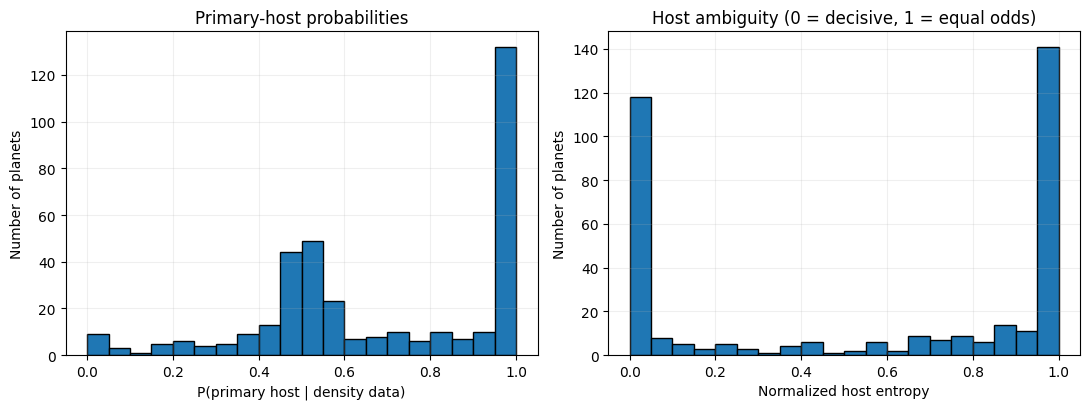

,KOI,KOIpl,rho_transit_gcm3,sigma_transit_gcm3,rho1_joint_gcm3,rho2_joint_gcm3,p_pri,p_sec,host_MAP,host_entropy_nats,host_entropy_normalized,host_confidence,host_probability_valid
0,42,42.01,1.72198,0.131390,0.700686,3.046455,0.509663,4.903370e-01,primary,6.929604e-01,9.997306e-01,0.019326,True
1,112,112.01,1.79031,0.128355,1.155487,2.177612,0.005253,9.947471e-01,secondary,3.281145e-02,4.733692e-02,0.989494,True
2,112,112.02,1.77451,0.319880,1.155487,2.177612,0.271916,7.280838e-01,secondary,5.851554e-01,8.442008e-01,0.456168,True
3,162,162.01,0.71331,0.472690,1.265270,2.028422,0.814739,1.852613e-01,primary,4.792784e-01,6.914526e-01,0.629477,True
4,163,163.01,0.94776,1.036495,2.734749,2.955435,0.588599,4.114008e-01,primary,6.773643e-01,9.772302e-01,0.177198,True
5,165,165.01,4.04712,1.023485,2.145429,3.491112,0.185437,8.145632e-01,secondary,4.795383e-01,6.918275e-01,0.629126,True
6,174,174.01,2.63903,4.865140,2.953764,13.874349,0.932912,6.708758e-02,primary,2.460394e-01,3.549599e-01,0.865825,True
7,177,177.01,1.23168,0.229375,1.341670,1.563564,0.616070,3.839304e-01,primary,6.659555e-01,9.607707e-01,0.232139,True
8,191,191.01,1.85072,0.081680,2.012917,5.355838,1.000000,1.153428e-28,primary,2.863100e-11,4.130580e-11,1.000000,True
9,191,191.02,2.46233,0.448050,2.012917,5.355838,0.999999,7.266428e-07,primary,1.099762e-05,1.586621e-05,0.999999,True


Saved host-probability catalogue: C:\Users\Lenovo\Downloads\Binaries\data\processed\binary_host_probability_catalog.csv
Saved summary: C:\Users\Lenovo\Downloads\Binaries\data\processed\binary_host_probability_summary.csv
Saved sensitivity results: C:\Users\Lenovo\Downloads\Binaries\data\processed\binary_host_probability_sensitivity.csv
Final integrity checks passed.


In [6]:
# Compact summary of probability strength and data coverage.
valid = df["host_probability_valid"].to_numpy(bool)
summary = pd.DataFrame([
    {"metric": "input_file", "value": str(INPUT_FILE)},
    {"metric": "density_model", "value": model_family},
    {"metric": "density_uncertainty_source", "value": uncertainty_source},
    {"metric": "n_planet_rows", "value": len(df)},
    {"metric": "n_valid_host_probabilities", "value": int(valid.sum())},
    {"metric": "n_invalid_host_probabilities", "value": int((~valid).sum())},
    {"metric": "median_p_primary_valid_rows", "value": float(df.loc[valid, "p_pri"].median()) if valid.any() else np.nan},
    {"metric": "fraction_primary_probability_gt_0_9", "value": float((df.loc[valid, "p_pri"] > 0.9).mean()) if valid.any() else np.nan},
    {"metric": "fraction_secondary_probability_gt_0_9", "value": float((df.loc[valid, "p_sec"] > 0.9).mean()) if valid.any() else np.nan},
    {"metric": "fraction_ambiguous_p_primary_0_1_to_0_9", "value": float(df.loc[valid, "p_pri"].between(0.1, 0.9).mean()) if valid.any() else np.nan},
    {"metric": "prior_primary", "value": P_PRIOR_PRIMARY},
    {"metric": "prior_secondary", "value": P_PRIOR_SECONDARY},
])

display(summary)

# Probability distribution diagnostics.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(df.loc[valid, "p_pri"].dropna(), bins=np.linspace(0, 1, 21), edgecolor="black")
axes[0].set_xlabel("P(primary host | density data)")
axes[0].set_ylabel("Number of planets")
axes[0].set_title("Primary-host probabilities")
axes[0].grid(alpha=0.2)

axes[1].hist(df.loc[valid, "host_entropy_normalized"].dropna(), bins=np.linspace(0, 1, 21), edgecolor="black")
axes[1].set_xlabel("Normalized host entropy")
axes[1].set_ylabel("Number of planets")
axes[1].set_title("Host ambiguity (0 = decisive, 1 = equal odds)")
axes[1].grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Keep relevant identification, density, probability and audit fields visible.
preferred_cols = [
    "KOI", "KOIpl", "rho_transit_gcm3", "sigma_transit_gcm3",
    RHO1_COL, RHO2_COL, "p_pri", "p_sec", "host_MAP",
    "host_entropy_nats", "host_entropy_normalized", "host_confidence",
    "host_probability_valid",
]
preview_cols = [c for c in preferred_cols if c in df.columns]
display(df[preview_cols].head(20))

# Save only after checks have passed.
df.to_csv(OUTPUT_FILE, index=False)
summary.to_csv(SUMMARY_FILE, index=False)
sensitivity.to_csv(SENSITIVITY_FILE, index=False)

print("Saved host-probability catalogue:", OUTPUT_FILE.resolve())
print("Saved summary:", SUMMARY_FILE.resolve())
print("Saved sensitivity results:", SENSITIVITY_FILE.resolve())

# Final output integrity checks.
assert df["_planet_key"].is_unique, "Output contains duplicate planet IDs."
assert len(df) == df["KOIpl"].notna().sum(), "Unexpected rows without planet IDs."
print("Final integrity checks passed.")

## Interpretation notes

- `p_pri = 0.9` means the primary is favored at 90% under this particular likelihood and prior; it is not a calibrated 90% guarantee.
- Strongly unequal probabilities can reflect the model-scatter assumption, transit-density systematics, or eccentricity, as well as host identity.
- The MIST density estimate in the current pipeline is based on a MIST-derived mass and catalogue radius; it is not necessarily a density calculated from a MIST-predicted radius. Check the exact source columns when describing the method.
- Before the final radius-gap analysis, validate probability sensitivity and document any rows with invalid/missing density data. Do not tune the uncertainty model to make host probabilities look more decisive.